## NicheJepa Model training

Creator: Mohammad Vali Sanian (mohammad.sanian@helsinki.fi) (mv10@sanger.ac.uk).

Date of Creation: 31.08.2024

Date of Last Modification: 1.09.2024

# 1. Setup

## 1.1 Libraries 

In [1]:
import torch
import os
import logging
import anndata as ad
import scanpy as sc
from sklearn.metrics.pairwise import cosine_similarity
from src.nichejepa.train import train
from src.nichejepa.eval import evaluation
from src.nichejepa.utils.config_utils import create_params_from_YAML_wandb_config, prepare_dataset
from src.nichejepa.utils.distributed import init_distributed
from src.nichejepa.utils.eval_utils import clustering_metrics, classification_metrics
import numpy as np


## 1.2 Create params
All setup will be done in the config file. Please edit that file to continue.

In [2]:
rank=0
logging.basicConfig()
logger = logging.getLogger()
logger.setLevel(logging.INFO if rank == 0 else logging.ERROR)
params = create_params_from_YAML_wandb_config('configs/simulated_100k.yaml',logger)

INFO:root:Loaded parameters from YAML file.


## 1.3 Create Train,Test dataset

In [3]:
train_dataset, test_dataset = prepare_dataset(params)
train_dataset

Dataset({
    features: ['gene_tokens_cell', 'gene_tokens_neighborhood', 'cell_types', 'niche_types', 'n_nonzero_cell_tokens', 'n_nonzero_neighborhood_tokens', 'n_nonzero_tokens', 'input_ids'],
    num_rows: 80000
})

## 1.4 INIT distributed (it should change later)

In [5]:
devices=['cuda:1']
world_size=1
os.environ['CUDA_VISIBLE_DEVICES'] = str(devices[rank].split(':')[-1])

logging.basicConfig()
logger = logging.getLogger()
logger.setLevel(logging.INFO if rank == 0 else logging.ERROR)

world_size, rank = init_distributed(rank_and_world_size=(rank, world_size), port=40321)
logger.info(f'Running... (rank: {rank}/{world_size})')

INFO:root:Running... (rank: 0/1)


# 2.Model Training With just_cell and just_neighborhood as True

## 2.1 Train Model

In [ ]:
params['data']['just_cell'] = True
params['data']['just_neighborhood'] = True

params['mask']['n_contexts'] = 1
params['mask']['n_targets'] = 9
params['mask']['per_segment_mask_ratio'] = 0.2


params['meta']['pred_emb_dim'] = 192
params['meta']['enc_emb_dim'] = 384
params['meta']['pred_depth'] = 1
params['meta']['enc_depth'] = 3

params['optimization']['pos_learnable'] = 0
params['optimization']['seg_learnable'] = 0
params['optimization']['epochs'] = 40

train(params, train_dataset, test_dataset)

# 3. Analysis With just_cell and just_neighborhood as True

## 3.1 Cell Type Average

In [6]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=True
params['emb']['cls']=False
params['data']['just_cell'] = True
params['data']['just_neighborhood'] = True

params['mask']['n_contexts'] = 1
params['mask']['n_targets'] = 9
params['mask']['per_segment_mask_ratio'] = 0.2


params['meta']['pred_emb_dim'] = 192
params['meta']['enc_emb_dim'] = 384
params['meta']['pred_depth'] = 1
params['meta']['enc_depth'] = 3

params['optimization']['pos_learnable'] = 0
params['optimization']['seg_learnable'] = 0
params['optimization']['epochs'] = 40

adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 384, padding_idx=0)
  (seg_embed): Embedding(3, 384, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=384, out_features=1152, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=384, out_features=384, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=384, out_features=1536, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=1536, out_features=384, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
)
INFO:root:Data loader created.
INFO:root:Data loader 

2963it [01:36, 30.67it/s]
741it [00:23, 31.33it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/simulated_100k_pred_depth_1_pred_emb_dim_192_enc_depth_3_enc_emb_dim_384_n_targets_9_n_contexts_1_target_mask_size_10_context_mask_size_1240_num_epochs_40_seq_len_cell_374_pos_learnable_0_seg_learnable_0_seq_len_neighborhood_1105_total/extracted_features/cell_embedding_average.h5ad


### 3.1.1 Feature Analysis

In [7]:
import anndata as ad
print(adata)

print(cosine_similarity(adata.obsm['jepa_emb'][:100, :]))
adata.obsm['jepa_emb']
#adata.obsm['jepa_emb']




AnnData object with n_obs × n_vars = 100000 × 0
    obs: 'split', 'label_name', 'retrieve_label', 'retrieve_position_emb', 'retrieve_emb_from_layer', 'cell_type', 'gene_count'
    obsm: 'jepa_emb'
[[1.0000002  0.9998812  0.999856   ... 0.99987197 0.9998672  0.9998816 ]
 [0.9998812  0.9999998  0.99988306 ... 0.99989873 0.9998777  0.99989337]
 [0.999856   0.99988306 1.0000001  ... 0.9999057  0.9998454  0.9998709 ]
 ...
 [0.99987197 0.99989873 0.9999057  ... 1.         0.9998715  0.99989724]
 [0.9998672  0.9998777  0.9998454  ... 0.9998715  1.0000002  0.9998832 ]
 [0.9998816  0.99989337 0.9998709  ... 0.99989724 0.9998832  0.9999999 ]]


array([[-3.0410016 , -0.4465261 ,  0.61798084, ...,  1.3859231 ,
        -0.23742206, -1.2890204 ],
       [-3.0485263 , -0.48029354,  0.6181399 , ...,  1.3608402 ,
        -0.25082606, -1.3035637 ],
       [-3.044746  , -0.464977  ,  0.618201  , ...,  1.3504919 ,
        -0.25568062, -1.2782452 ],
       ...,
       [-3.0484114 , -0.47697613,  0.63032   , ...,  1.3562441 ,
        -0.23870647, -1.2999662 ],
       [-3.039362  , -0.4772521 ,  0.6206992 , ...,  1.3463569 ,
        -0.25563672, -1.2814294 ],
       [-3.045621  , -0.4812911 ,  0.61490446, ...,  1.3538009 ,
        -0.24417204, -1.2974734 ]], dtype=float32)

### 3.1.2 Umap

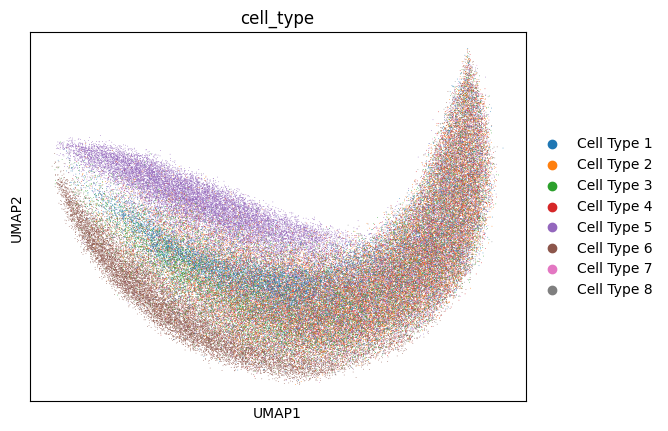

In [8]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

### 3.1.3 Logistic regression

In [9]:
classification_metrics(adata, label_col='cell_type', classifier='logistic')

/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Test Accuracy: 0.66
Test F1 Score: 0.64
Train Accuracy: 0.66
Train F1 Score: 0.65


{'test_accuracy': 0.65905,
 'test_f1': 0.6440655739294352,
 'train_accuracy': 0.6631375,
 'train_f1': 0.647775822533176}

### 3.1.4 KNeighborsClassifier

In [10]:
classification_metrics(adata, label_col='cell_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.53
Test F1 Score: 0.51
Train Accuracy: 0.69
Train F1 Score: 0.68


{'test_accuracy': 0.529,
 'test_f1': 0.5095413626552521,
 'train_accuracy': 0.692275,
 'train_f1': 0.6816010824613271}

### 3.1.5 nmi&ari

In [11]:
clustering_metrics(adata,label_col='cell_type')

INFO:jax._src.xla_bridge:Unable to initialize backend 'cuda': 
INFO:jax._src.xla_bridge:Unable to initialize backend 'rocm': module 'jaxlib.xla_extension' has no attribute 'GpuAllocatorConfig'
INFO:jax._src.xla_bridge:Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
NMI (Normalized Mutual Information): 0.04176815696578485
ARI (Adjusted Rand Index): 0.016609767735124778


{'nmi': 0.04176815696578485, 'ari': 0.016609767735124778}

## 3.2 Cell Type CLS

In [12]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=False
params['emb']['cls']=True

params['data']['just_cell'] = True
params['data']['just_neighborhood'] = True

params['mask']['n_contexts'] = 1
params['mask']['n_targets'] = 9
params['mask']['per_segment_mask_ratio'] = 0.2


params['meta']['pred_emb_dim'] = 192
params['meta']['enc_emb_dim'] = 384

params['meta']['pred_depth'] = 1
params['meta']['enc_depth'] = 3

params['optimization']['pos_learnable'] = 0
params['optimization']['seg_learnable'] = 0
params['optimization']['epochs'] = 40

adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 384, padding_idx=0)
  (seg_embed): Embedding(3, 384, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=384, out_features=1152, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=384, out_features=384, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=384, out_features=1536, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=1536, out_features=384, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
)
INFO:root:Data loader created.
INFO:root:Data loader 

/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
2961it [01:35, 32.14it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
2963it [01:35, 30.89it/s]
741it [00:23, 31.00it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/simulated_100k_pred_depth_1_pred_emb_dim_192_enc_depth_3_enc_emb_dim_384_n_targets_9_n_contexts_1_target_mask_size_10_context_mask_size_1240_num_epochs_40_seq_len_cell_374_pos_learnable_0_seg_learnable_0_seq_len_neighborhood_1105_total/extracted_features/cell_embedding_cls.h5ad


### 3.2.1 Feature Analysis

In [13]:
print(cosine_similarity(adata.obsm['jepa_emb'][:100, :]))
adata.obsm['jepa_emb']
adata.obsm['jepa_emb']

[[1.0000001  0.9999994  0.9999993  ... 0.99999994 0.99999964 0.9999996 ]
 [0.9999994  1.         0.99999917 ... 0.99999934 0.9999995  0.99999946]
 [0.9999993  0.99999917 1.0000001  ... 0.99999917 0.99999905 0.9999994 ]
 ...
 [0.99999994 0.99999934 0.99999917 ... 1.0000001  1.         0.9999994 ]
 [0.99999964 0.9999995  0.99999905 ... 1.         1.0000001  0.99999964]
 [0.9999996  0.99999946 0.9999994  ... 0.9999994  0.99999964 0.9999999 ]]


array([[-2.9365735 , -0.41945732,  0.8263039 , ...,  1.2693344 ,
        -0.34385896, -1.466577  ],
       [-2.9376748 , -0.4206    ,  0.8285412 , ...,  1.269889  ,
        -0.34404424, -1.4669466 ],
       [-2.9375224 , -0.42082837,  0.825235  , ...,  1.2694122 ,
        -0.344368  , -1.4674811 ],
       ...,
       [-2.936413  , -0.42137477,  0.82624096, ...,  1.2715886 ,
        -0.34418598, -1.4664192 ],
       [-2.9365537 , -0.4210069 ,  0.8256204 , ...,  1.2686145 ,
        -0.34369335, -1.468468  ],
       [-2.9368546 , -0.42039716,  0.82586044, ...,  1.2701355 ,
        -0.34332114, -1.4705377 ]], dtype=float32)

### 3.2.2 Umap

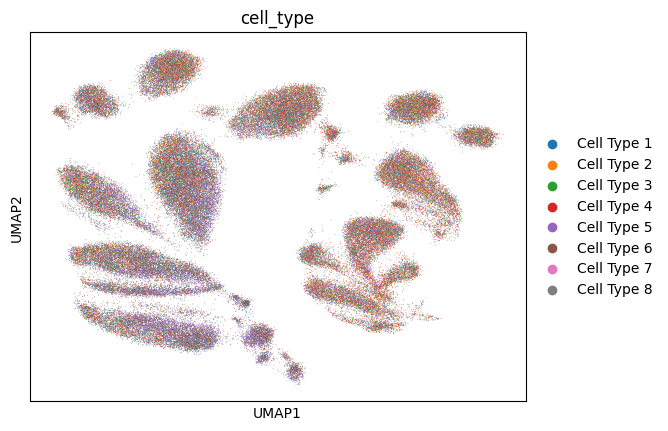

In [14]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

### 3.2.3 Logistic regression

In [15]:
classification_metrics(adata, label_col='cell_type', classifier='logistic')

Test Accuracy: 0.24
Test F1 Score: 0.15
Train Accuracy: 0.24
Train F1 Score: 0.15


{'test_accuracy': 0.2449,
 'test_f1': 0.15040439525047108,
 'train_accuracy': 0.2441125,
 'train_f1': 0.15070865936050112}

### 3.2.4 KNeighborsClassifier

In [16]:
classification_metrics(adata, label_col='cell_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.29
Test F1 Score: 0.28
Train Accuracy: 0.52
Train F1 Score: 0.51


{'test_accuracy': 0.29015,
 'test_f1': 0.28095181834085026,
 'train_accuracy': 0.5246875,
 'train_f1': 0.5149554118623005}

### 3.2.5 nmi&ari

In [17]:
clustering_metrics(adata,label_col='cell_type')

NMI (Normalized Mutual Information): 0.030452960468871384
ARI (Adjusted Rand Index): 0.014896736403217441


{'nmi': 0.030452960468871384, 'ari': 0.014896736403217441}

## 3.3 Cell Type weighted_average

In [18]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=True
params['emb']['average']=False
params['emb']['cls']=False

params['data']['just_cell'] = True
params['data']['just_neighborhood'] = True

params['mask']['n_contexts'] = 1
params['mask']['n_targets'] = 9
params['mask']['per_segment_mask_ratio'] = 0.2


params['meta']['pred_emb_dim'] = 192
params['meta']['enc_emb_dim'] = 384

params['meta']['pred_depth'] = 1
params['meta']['enc_depth'] = 3

params['optimization']['pos_learnable'] = 0
params['optimization']['seg_learnable'] = 0
params['optimization']['epochs'] = 40

adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 384, padding_idx=0)
  (seg_embed): Embedding(3, 384, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=384, out_features=1152, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=384, out_features=384, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=384, out_features=1536, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=1536, out_features=384, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
)
INFO:root:Data loader created.
INFO:root:Data loader 

/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
2962it [01:34, 32.17it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
2963it [01:34, 31.28it/s]
741it [00:23, 31.05it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/simulated_100k_pred_depth_1_pred_emb_dim_192_enc_depth_3_enc_emb_dim_384_n_targets_9_n_contexts_1_target_mask_size_10_context_mask_size_1240_num_epochs_40_seq_len_cell_374_pos_learnable_0_seg_learnable_0_seq_len_neighborhood_1105_total/extracted_features/cell_embedding_weighted_average.h5ad


### 3.3.1 Feature Analysis

In [19]:
print(cosine_similarity(adata.obsm['jepa_emb'][:100, :]))
adata.obsm['jepa_emb']
adata.obsm['jepa_emb']

[[0.9999999  0.9999758  0.99997103 ... 0.9999741  0.9999745  0.9999752 ]
 [0.9999758  1.0000002  0.99997616 ... 0.9999763  0.99997616 0.9999769 ]
 [0.99997103 0.99997616 1.0000004  ... 0.99997723 0.99996936 0.9999748 ]
 ...
 [0.9999741  0.9999763  0.99997723 ... 0.9999998  0.99997485 0.9999783 ]
 [0.9999745  0.99997616 0.99996936 ... 0.99997485 1.         0.9999773 ]
 [0.9999752  0.9999769  0.9999748  ... 0.9999783  0.9999773  1.0000001 ]]


array([[-3.053121  , -0.4302723 ,  0.595725  , ...,  1.3610847 ,
        -0.22189976, -1.3044299 ],
       [-3.0546122 , -0.44493836,  0.59781414, ...,  1.3527315 ,
        -0.22776097, -1.3053656 ],
       [-3.0558472 , -0.43863097,  0.59823203, ...,  1.3522487 ,
        -0.22901392, -1.2986977 ],
       ...,
       [-3.053807  , -0.4417743 ,  0.6028045 , ...,  1.3506302 ,
        -0.22374749, -1.3074746 ],
       [-3.0536432 , -0.443248  ,  0.59698266, ...,  1.3442793 ,
        -0.22592637, -1.2954698 ],
       [-3.057722  , -0.4467591 ,  0.597002  , ...,  1.3520817 ,
        -0.22379683, -1.3047458 ]], dtype=float32)

### 3.3.2 Umap

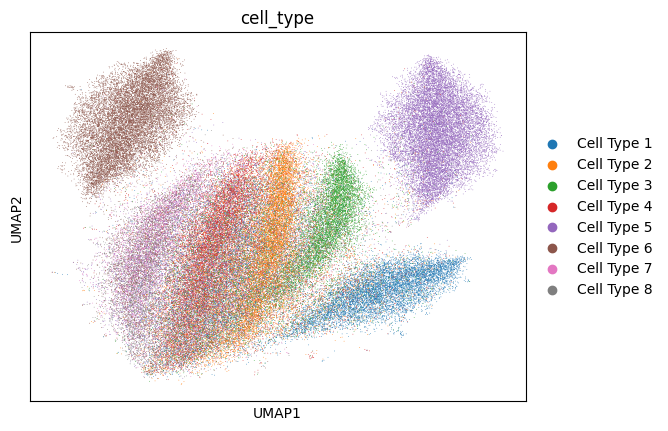

In [20]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

### 3.3.3 Logistic regression

In [21]:
classification_metrics(adata, label_col='cell_type', classifier='logistic')

/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Test Accuracy: 0.66
Test F1 Score: 0.64
Train Accuracy: 0.66
Train F1 Score: 0.64


{'test_accuracy': 0.66265,
 'test_f1': 0.6384719641133323,
 'train_accuracy': 0.661925,
 'train_f1': 0.6382496040816996}

### 3.3.4 KNN

In [22]:
classification_metrics(adata, label_col='cell_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.65
Test F1 Score: 0.65
Train Accuracy: 0.75
Train F1 Score: 0.75


{'test_accuracy': 0.647,
 'test_f1': 0.6458527763724329,
 'train_accuracy': 0.7517,
 'train_f1': 0.7516818197458984}

### 3.3.5 nmi&ari

In [23]:
clustering_metrics(adata,label_col='cell_type')

NMI (Normalized Mutual Information): 0.2925912750859688
ARI (Adjusted Rand Index): 0.16759362593237745


{'nmi': 0.2925912750859688, 'ari': 0.16759362593237745}

## 3.4 Niche Type Average

In [24]:
params['emb']['retrieve_cell'] = False
params['emb']['retrieve_niche'] = True
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=True
params['emb']['cls']=False

params['data']['just_cell'] = True
params['data']['just_neighborhood'] = True

params['mask']['n_contexts'] = 1
params['mask']['n_targets'] = 9
params['mask']['per_segment_mask_ratio'] = 0.2


params['meta']['pred_emb_dim'] = 192
params['meta']['enc_emb_dim'] = 384

params['meta']['pred_depth'] = 1
params['meta']['enc_depth'] = 3

params['optimization']['pos_learnable'] = 0
params['optimization']['seg_learnable'] = 0
params['optimization']['epochs'] = 40

adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 384, padding_idx=0)
  (seg_embed): Embedding(3, 384, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=384, out_features=1152, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=384, out_features=384, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=384, out_features=1536, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=1536, out_features=384, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
)
INFO:root:Data loader created.
INFO:root:Data loader 

/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
2962it [01:34, 32.07it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
2963it [01:34, 31.45it/s]
741it [00:23, 31.18it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'niche_type' as categorical


AnnData has been successfully saved at: logs/simulated_100k_pred_depth_1_pred_emb_dim_192_enc_depth_3_enc_emb_dim_384_n_targets_9_n_contexts_1_target_mask_size_10_context_mask_size_1240_num_epochs_40_seq_len_cell_374_pos_learnable_0_seg_learnable_0_seq_len_neighborhood_1105_total/extracted_features/niche_embedding_average.h5ad


### 3.4.1 Feature Analysis

In [25]:
print(cosine_similarity(adata.obsm['jepa_emb'][:100, :]))
adata.obsm['jepa_emb']
adata.obsm['jepa_emb']

[[1.         0.9999999  0.9999999  ... 0.99999964 1.         1.        ]
 [0.9999999  1.0000001  0.99999976 ... 0.9999999  1.         0.9999999 ]
 [0.9999999  0.99999976 0.9999999  ... 1.0000001  0.99999964 0.9999999 ]
 ...
 [0.99999964 0.9999999  1.0000001  ... 0.9999999  0.99999976 0.9999999 ]
 [1.         1.         0.99999964 ... 0.99999976 1.0000002  0.9999999 ]
 [1.         0.9999999  0.9999999  ... 0.9999999  0.9999999  0.9999999 ]]


array([[-3.0571456 , -0.41493157,  0.58167195, ...,  1.345974  ,
        -0.2020346 , -1.3043786 ],
       [-3.0572128 , -0.41621855,  0.5816076 , ...,  1.3456167 ,
        -0.20293164, -1.3035845 ],
       [-3.0564315 , -0.41563478,  0.5809013 , ...,  1.3462676 ,
        -0.2023031 , -1.3038807 ],
       ...,
       [-3.0576472 , -0.4157949 ,  0.58113265, ...,  1.3478378 ,
        -0.20236872, -1.3034666 ],
       [-3.0590436 , -0.415356  ,  0.581421  , ...,  1.3460064 ,
        -0.20246068, -1.3035108 ],
       [-3.0577643 , -0.41570857,  0.58168024, ...,  1.3467344 ,
        -0.20142469, -1.3039845 ]], dtype=float32)

### 3.4.2 Umap

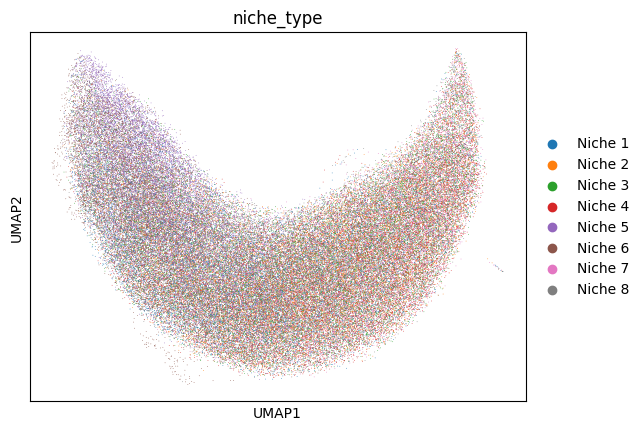

In [26]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='niche_type')

### 3.4.3 Logistic regression

In [27]:
classification_metrics(adata, label_col='niche_type', classifier='logistic')

Test Accuracy: 0.25
Test F1 Score: 0.15
Train Accuracy: 0.25
Train F1 Score: 0.15


{'test_accuracy': 0.248,
 'test_f1': 0.15302172270457928,
 'train_accuracy': 0.2492125,
 'train_f1': 0.1535953324302353}

### 3.4.4 KNN

In [28]:
classification_metrics(adata, label_col='niche_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.47
Test F1 Score: 0.45
Train Accuracy: 0.67
Train F1 Score: 0.66


{'test_accuracy': 0.4687,
 'test_f1': 0.4480519675566032,
 'train_accuracy': 0.6667,
 'train_f1': 0.6551715629581325}

### 3.4.5 nmi&ari

In [29]:
clustering_metrics(adata,label_col='niche_type')

NMI (Normalized Mutual Information): 0.08782100519060518
ARI (Adjusted Rand Index): 0.04676663148315945


{'nmi': 0.08782100519060518, 'ari': 0.04676663148315945}

## 3.5 Niche Type CLS

In [30]:
params['emb']['retrieve_cell'] = False
params['emb']['retrieve_niche'] = True
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=False
params['emb']['cls']=True

params['data']['just_cell'] = True
params['data']['just_neighborhood'] = True


params['mask']['n_contexts'] = 1
params['mask']['n_targets'] = 9
params['mask']['per_segment_mask_ratio'] = 0.2


params['meta']['pred_emb_dim'] = 192
params['meta']['enc_emb_dim'] = 384

params['meta']['pred_depth'] = 1
params['meta']['enc_depth'] = 3

params['optimization']['pos_learnable'] = 0
params['optimization']['seg_learnable'] = 0
params['optimization']['epochs'] = 40


adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 384, padding_idx=0)
  (seg_embed): Embedding(3, 384, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=384, out_features=1152, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=384, out_features=384, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=384, out_features=1536, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=1536, out_features=384, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
)
INFO:root:Data loader created.
INFO:root:Data loader 

/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
2962it [01:34, 32.19it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
2963it [01:34, 31.43it/s]
741it [00:23, 31.53it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'niche_type' as categorical


AnnData has been successfully saved at: logs/simulated_100k_pred_depth_1_pred_emb_dim_192_enc_depth_3_enc_emb_dim_384_n_targets_9_n_contexts_1_target_mask_size_10_context_mask_size_1240_num_epochs_40_seq_len_cell_374_pos_learnable_0_seg_learnable_0_seq_len_neighborhood_1105_total/extracted_features/niche_embedding_cls.h5ad


### 3.5.1 Feature Analysis

In [31]:
print(cosine_similarity(adata.obsm['jepa_emb'][:100, :]))
adata.obsm['jepa_emb']
adata.obsm['jepa_emb']

[[1.0000001  0.9999994  0.9999993  ... 0.99999994 0.99999964 0.9999996 ]
 [0.9999994  1.         0.99999917 ... 0.99999934 0.9999995  0.99999946]
 [0.9999993  0.99999917 1.0000001  ... 0.99999917 0.99999905 0.9999994 ]
 ...
 [0.99999994 0.99999934 0.99999917 ... 1.0000001  1.         0.9999994 ]
 [0.99999964 0.9999995  0.99999905 ... 1.         1.0000001  0.99999964]
 [0.9999996  0.99999946 0.9999994  ... 0.9999994  0.99999964 0.9999999 ]]


array([[-2.9365735 , -0.41945732,  0.8263039 , ...,  1.2693344 ,
        -0.34385896, -1.466577  ],
       [-2.9376748 , -0.4206    ,  0.8285412 , ...,  1.269889  ,
        -0.34404424, -1.4669466 ],
       [-2.9375224 , -0.42082837,  0.825235  , ...,  1.2694122 ,
        -0.344368  , -1.4674811 ],
       ...,
       [-2.936413  , -0.42137477,  0.82624096, ...,  1.2715886 ,
        -0.34418598, -1.4664192 ],
       [-2.9365537 , -0.4210069 ,  0.8256204 , ...,  1.2686145 ,
        -0.34369335, -1.468468  ],
       [-2.9368546 , -0.42039716,  0.82586044, ...,  1.2701355 ,
        -0.34332114, -1.4705377 ]], dtype=float32)

### 3.5.2 Umap

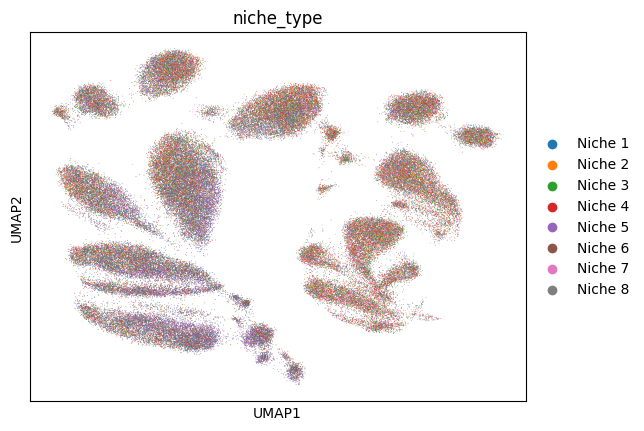

In [32]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='niche_type')

### 3.5.3 Logistic regression

In [33]:
classification_metrics(adata, label_col='niche_type', classifier='logistic')

Test Accuracy: 0.24
Test F1 Score: 0.16
Train Accuracy: 0.24
Train F1 Score: 0.16


{'test_accuracy': 0.24145,
 'test_f1': 0.1615901576610754,
 'train_accuracy': 0.2423375,
 'train_f1': 0.16185112702527685}

### 3.5.4 KNN

In [34]:
classification_metrics(adata, label_col='niche_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.28
Test F1 Score: 0.27
Train Accuracy: 0.52
Train F1 Score: 0.51


{'test_accuracy': 0.28025,
 'test_f1': 0.27266823302094045,
 'train_accuracy': 0.5178,
 'train_f1': 0.5118330116249029}

### 3.5.5 nmi&ari

In [35]:
clustering_metrics(adata,label_col='niche_type')

NMI (Normalized Mutual Information): 0.07001046954196664
ARI (Adjusted Rand Index): 0.03556824920232163


{'nmi': 0.07001046954196664, 'ari': 0.03556824920232163}

## 3.6 Niche Type weighted_average

In [36]:
params['emb']['retrieve_cell'] = False
params['emb']['retrieve_niche'] = True
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=True
params['emb']['average']=False
params['emb']['cls']=False

params['data']['just_cell'] = True
params['data']['just_neighborhood'] = True


params['mask']['n_contexts'] = 1
params['mask']['n_targets'] = 9
params['mask']['per_segment_mask_ratio'] = 0.2


params['meta']['pred_emb_dim'] = 192
params['meta']['enc_emb_dim'] = 384

params['meta']['pred_depth'] = 1
params['meta']['enc_depth'] = 3

params['optimization']['pos_learnable'] = 0
params['optimization']['seg_learnable'] = 0
params['optimization']['epochs'] = 40

adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 384, padding_idx=0)
  (seg_embed): Embedding(3, 384, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=384, out_features=1152, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=384, out_features=384, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=384, out_features=1536, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=1536, out_features=384, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
)
INFO:root:Data loader created.
INFO:root:Data loader 

/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
2961it [01:34, 32.05it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
2963it [01:34, 31.27it/s]
741it [00:24, 30.68it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'niche_type' as categorical


AnnData has been successfully saved at: logs/simulated_100k_pred_depth_1_pred_emb_dim_192_enc_depth_3_enc_emb_dim_384_n_targets_9_n_contexts_1_target_mask_size_10_context_mask_size_1240_num_epochs_40_seq_len_cell_374_pos_learnable_0_seg_learnable_0_seq_len_neighborhood_1105_total/extracted_features/niche_embedding_weighted_average.h5ad


### 3.6.1 Feature Analysis

In [37]:
print(cosine_similarity(adata.obsm['jepa_emb'][:100, :]))
adata.obsm['jepa_emb']
adata.obsm['jepa_emb']

[[0.9999999  0.9999758  0.99997103 ... 0.9999741  0.9999745  0.9999752 ]
 [0.9999758  1.0000002  0.99997616 ... 0.9999763  0.99997616 0.9999769 ]
 [0.99997103 0.99997616 1.0000004  ... 0.99997723 0.99996936 0.9999748 ]
 ...
 [0.9999741  0.9999763  0.99997723 ... 0.9999998  0.99997485 0.9999783 ]
 [0.9999745  0.99997616 0.99996936 ... 0.99997485 1.         0.9999773 ]
 [0.9999752  0.9999769  0.9999748  ... 0.9999783  0.9999773  1.0000001 ]]


array([[-3.053121  , -0.4302723 ,  0.595725  , ...,  1.3610847 ,
        -0.22189976, -1.3044299 ],
       [-3.0546122 , -0.44493836,  0.59781414, ...,  1.3527315 ,
        -0.22776097, -1.3053656 ],
       [-3.0558472 , -0.43863097,  0.59823203, ...,  1.3522487 ,
        -0.22901392, -1.2986977 ],
       ...,
       [-3.053807  , -0.4417743 ,  0.6028045 , ...,  1.3506302 ,
        -0.22374749, -1.3074746 ],
       [-3.0536432 , -0.443248  ,  0.59698266, ...,  1.3442793 ,
        -0.22592637, -1.2954698 ],
       [-3.057722  , -0.4467591 ,  0.597002  , ...,  1.3520817 ,
        -0.22379683, -1.3047458 ]], dtype=float32)

### 3.6.2 Umap

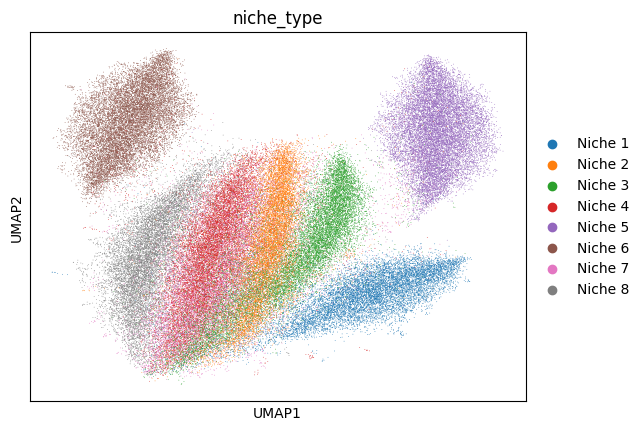

In [38]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='niche_type')

### 3.6.3 Logistic regression

In [39]:
classification_metrics(adata, label_col='niche_type', classifier='logistic')

Test Accuracy: 0.95
Test F1 Score: 0.95
Train Accuracy: 0.96
Train F1 Score: 0.96


{'test_accuracy': 0.95485,
 'test_f1': 0.95437376424744,
 'train_accuracy': 0.956425,
 'train_f1': 0.9559878946752931}

### 3.6.4 KNN

In [40]:
classification_metrics(adata, label_col='niche_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.98
Test F1 Score: 0.98
Train Accuracy: 0.99
Train F1 Score: 0.99


{'test_accuracy': 0.9795,
 'test_f1': 0.9794032563351348,
 'train_accuracy': 0.9892625,
 'train_f1': 0.9892393208050214}

### 3.6.5 nmi&ari

In [41]:
clustering_metrics(adata,label_col='niche_type')

NMI (Normalized Mutual Information): 0.4051933237460487
ARI (Adjusted Rand Index): 0.24509719712582362


{'nmi': 0.4051933237460487, 'ari': 0.24509719712582362}

## 3.7 Box plot of correlation between embeddings

In [42]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics.pairwise import cosine_similarity
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

def compute_similarity_stats(adata, embedding_key='jepa_emb', type_key='niche_type', n_samples=10000, random_state=42):
    """
    Function to compute mean and variance of cosine similarity between pairs of types (e.g., cell types).
    
    Parameters:
    - adata: AnnData object containing the data.
    - embedding_key: The key to use in .obsm for the embeddings (default: 'jepa_emb').
    - type_key: The key in .obs used to stratify and differentiate types (default: 'niche_type').
    - n_samples: Number of samples to draw from the dataset (default: 10000).
    - random_state: Seed for reproducibility (default: 42).
    
    Returns:
    - A DataFrame with mean and variance of cosine similarities between each pair of types.
    """
    
    # Stratified sampling based on the specified types
    types = adata.obs[type_key]
    if n_samples is not None:
      sampled_indices, _ = train_test_split(
        np.arange(adata.n_obs), 
        train_size=n_samples, 
        stratify=types, 
        random_state=random_state
      )
    
      # Subset the AnnData object to keep only the sampled cells
      adata_sampled = adata[sampled_indices].copy()
    else:
      adata_sampled = adata  
    # Extract the embeddings or the data matrix (from .obsm)
    data = adata_sampled.obsm[embedding_key]  # Replace with appropriate layer if necessary

    # Get the unique types
    unique_types = adata_sampled.obs[type_key].unique()

    # List to store the results for each class pair
    similarity_stats_list = []

    # Compute similarity between each pair of types
    for i, type_1 in enumerate(unique_types):
        for j, type_2 in enumerate(unique_types):
            # Select cells of the respective types
            cells_1 = data[adata_sampled.obs[type_key] == type_1]
            cells_2 = data[adata_sampled.obs[type_key] == type_2]

            # Compute pairwise cosine similarity between cells from type 1 and type 2
            similarity_matrix = cosine_similarity(cells_1, cells_2)
            # Compute mean and variance of the similarity scores
            mean_similarity = np.mean(similarity_matrix)
            variance_similarity = np.var(similarity_matrix)

            # Append results to the list
            similarity_stats_list.append({
                'Class 1': type_1,
                'Class 2': type_2,
                'Mean Similarity': mean_similarity,
                'Variance Similarity': variance_similarity
            })

    # Convert the list to a DataFrame
    similarity_stats = pd.DataFrame(similarity_stats_list)

    # Optionally print the resulting DataFrame
    print(similarity_stats)

    # Return the similarity stats DataFrame
    return similarity_stats

# Example usage:
# similarity_stats = compute_similarity_stats(adata)


In [43]:
import seaborn as sns
import matplotlib.pyplot as plt

def plot_similarity_heatmaps(similarity_stats, title_mean='Mean Similarity Between Types', title_variance='Variance of Similarity Between Types'):
    """
    Function to create and display two heatmaps for Mean Similarity and Variance Similarity side by side.
    
    Parameters:
    - similarity_stats: DataFrame containing the similarity statistics with 'Class 1', 'Class 2', 'Mean Similarity', and 'Variance Similarity'.
    - title_mean: Title for the mean similarity heatmap (default: 'Mean Similarity Between Types').
    - title_variance: Title for the variance similarity heatmap (default: 'Variance of Similarity Between Types').
    
    Returns:
    - Displays two heatmaps (Mean Similarity and Variance Similarity).
    """
    # Create pivot tables for mean similarity and variance similarity
    similarity_pivot_mean = similarity_stats.pivot(index='Class 1', columns='Class 2', values='Mean Similarity')
    similarity_pivot_variance = similarity_stats.pivot(index='Class 1', columns='Class 2', values='Variance Similarity')
    
    # Create the figure and two subplots side by side
    fig, axes = plt.subplots(1, 2, figsize=(18, 8))
    
    # Mean similarity heatmap
    sns.heatmap(similarity_pivot_mean, annot=True, cmap="coolwarm", cbar=True, fmt=".2f", ax=axes[0])
    axes[0].set_title(title_mean)
    axes[0].set_xlabel('Class 2')
    axes[0].set_ylabel('Class 1')
    
    # Variance similarity heatmap
    sns.heatmap(similarity_pivot_variance, annot=True, cmap="coolwarm", cbar=True, fmt=".2f", ax=axes[1])
    axes[1].set_title(title_variance)
    axes[1].set_xlabel('Class 2')
    axes[1].set_ylabel('Class 1')
    
    # Adjust the layout
    plt.tight_layout()
    
    # Display the heatmaps
    plt.show()

# Example usage:
# plot_similarity_heatmaps(similarity_stats)


### 3.7.1 Cell Type Average

        Class 1      Class 2  Mean Similarity  Variance Similarity
0   Cell Type 7  Cell Type 7         0.999868         7.673733e-10
1   Cell Type 7  Cell Type 6         0.999930         6.041410e-09
2   Cell Type 7  Cell Type 4         0.999878         9.236805e-10
3   Cell Type 7  Cell Type 2         0.999892         1.552834e-09
4   Cell Type 7  Cell Type 8         0.999867         9.626266e-10
..          ...          ...              ...                  ...
59  Cell Type 5  Cell Type 2         0.999978         1.631039e-08
60  Cell Type 5  Cell Type 8         0.999927         8.860590e-09
61  Cell Type 5  Cell Type 3         0.999976         1.416995e-08
62  Cell Type 5  Cell Type 1         0.999978         1.503846e-08
63  Cell Type 5  Cell Type 5         0.999989         1.611197e-08

[64 rows x 4 columns]


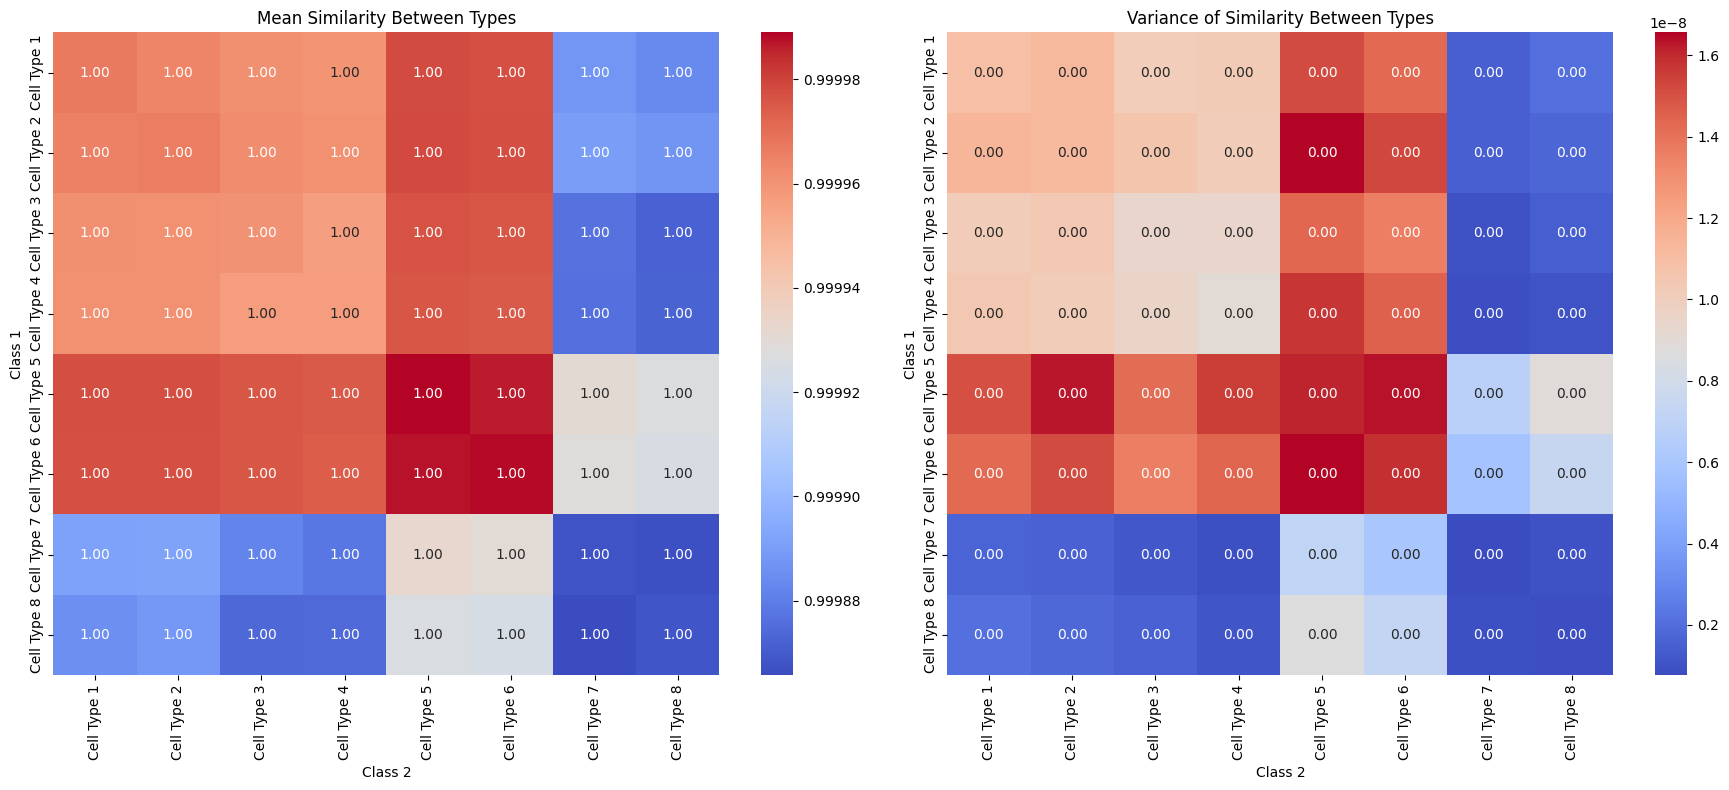

In [44]:
# File path
file_path = f'logs/simulated_100k_pred_depth_1_pred_emb_dim_192_enc_depth_3_enc_emb_dim_384_n_targets_9_n_contexts_1_target_mask_size_10_context_mask_size_1240_num_epochs_40_seq_len_cell_374_pos_learnable_0_seg_learnable_0_seq_len_neighborhood_1105_total/extracted_features/cell_embedding_average.h5ad'
adata = ad.read_h5ad(file_path)

# Load the .h5ad file
similarity_stats = compute_similarity_stats(adata,n_samples=None,type_key='cell_type')
plot_similarity_heatmaps(similarity_stats)

### 3.7.2 Cell Type CLS

        Class 1      Class 2  Mean Similarity  Variance Similarity
0   Cell Type 7  Cell Type 7              1.0         6.412982e-13
1   Cell Type 7  Cell Type 6              1.0         9.559598e-13
2   Cell Type 7  Cell Type 4              1.0         8.324253e-13
3   Cell Type 7  Cell Type 2              1.0         8.342357e-13
4   Cell Type 7  Cell Type 8              1.0         7.018781e-13
..          ...          ...              ...                  ...
59  Cell Type 5  Cell Type 2              1.0         9.611673e-13
60  Cell Type 5  Cell Type 8              1.0         1.312800e-12
61  Cell Type 5  Cell Type 3              1.0         9.822652e-13
62  Cell Type 5  Cell Type 1              1.0         8.982286e-13
63  Cell Type 5  Cell Type 5              1.0         9.762147e-13

[64 rows x 4 columns]


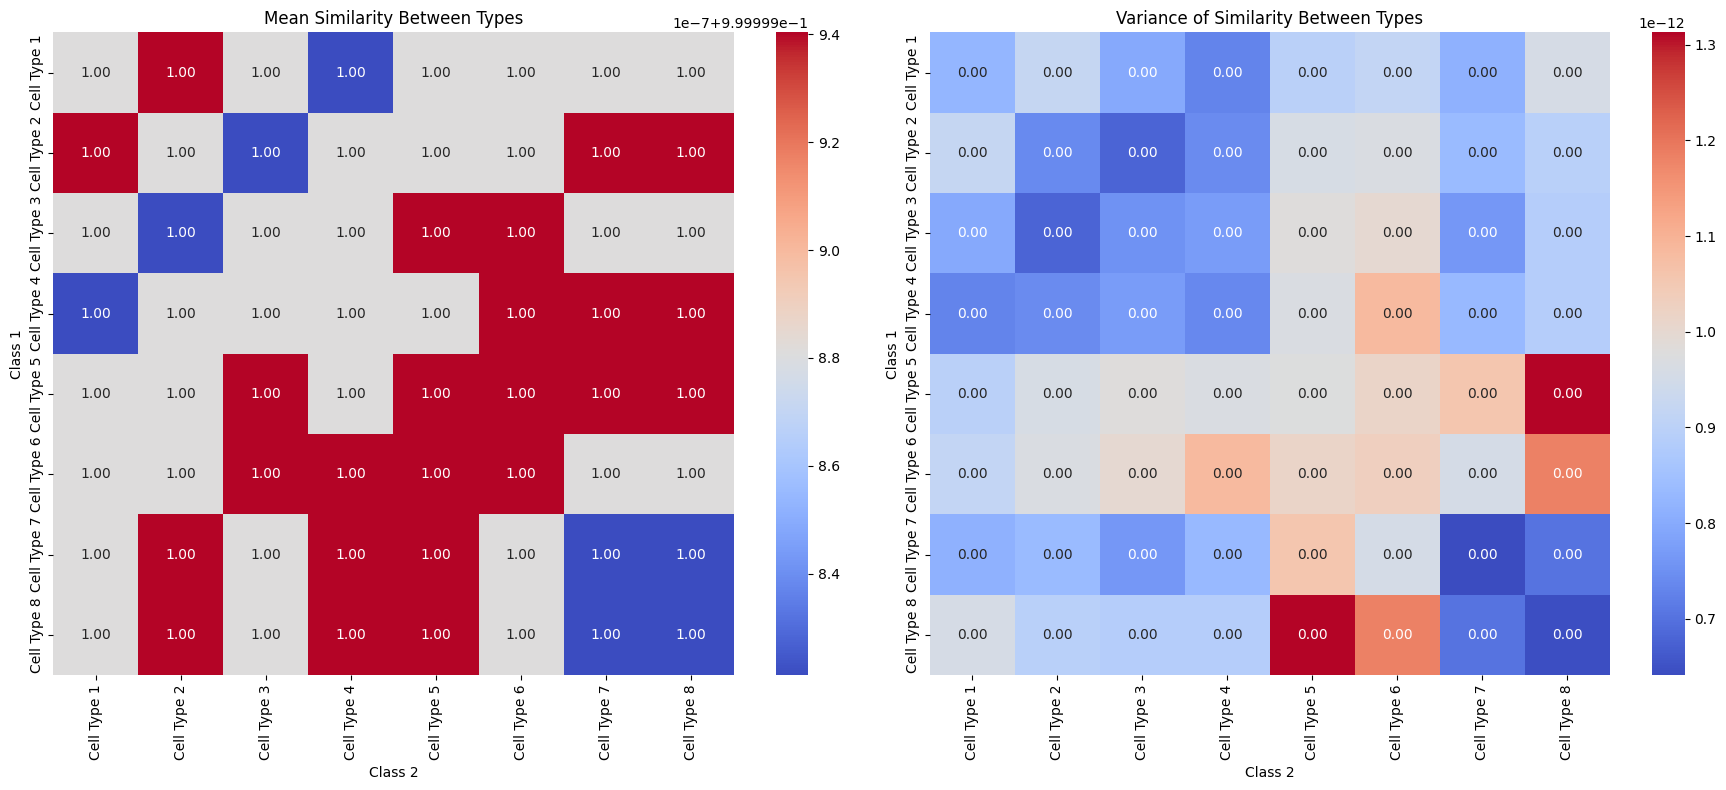

In [45]:
# File path
file_path = f'logs/simulated_100k_pred_depth_1_pred_emb_dim_192_enc_depth_3_enc_emb_dim_384_n_targets_9_n_contexts_1_target_mask_size_10_context_mask_size_1240_num_epochs_40_seq_len_cell_374_pos_learnable_0_seg_learnable_0_seq_len_neighborhood_1105_total/extracted_features/cell_embedding_cls.h5ad'
adata = ad.read_h5ad(file_path)

# Load the .h5ad file
similarity_stats = compute_similarity_stats(adata,n_samples=None,type_key='cell_type')
plot_similarity_heatmaps(similarity_stats)

### 3.7.3 Cell Type weighted Average

        Class 1      Class 2  Mean Similarity  Variance Similarity
0   Cell Type 7  Cell Type 7         0.999993         3.391459e-10
1   Cell Type 7  Cell Type 6         0.999998         6.966001e-10
2   Cell Type 7  Cell Type 4         0.999997         5.574813e-10
3   Cell Type 7  Cell Type 2         0.999998         5.856136e-10
4   Cell Type 7  Cell Type 8         0.999993         3.574702e-10
..          ...          ...              ...                  ...
59  Cell Type 5  Cell Type 2         0.999999         7.851767e-10
60  Cell Type 5  Cell Type 8         0.999997         7.899093e-10
61  Cell Type 5  Cell Type 3         0.999999         7.449891e-10
62  Cell Type 5  Cell Type 1         0.999999         7.860149e-10
63  Cell Type 5  Cell Type 5         1.000000         6.902247e-10

[64 rows x 4 columns]


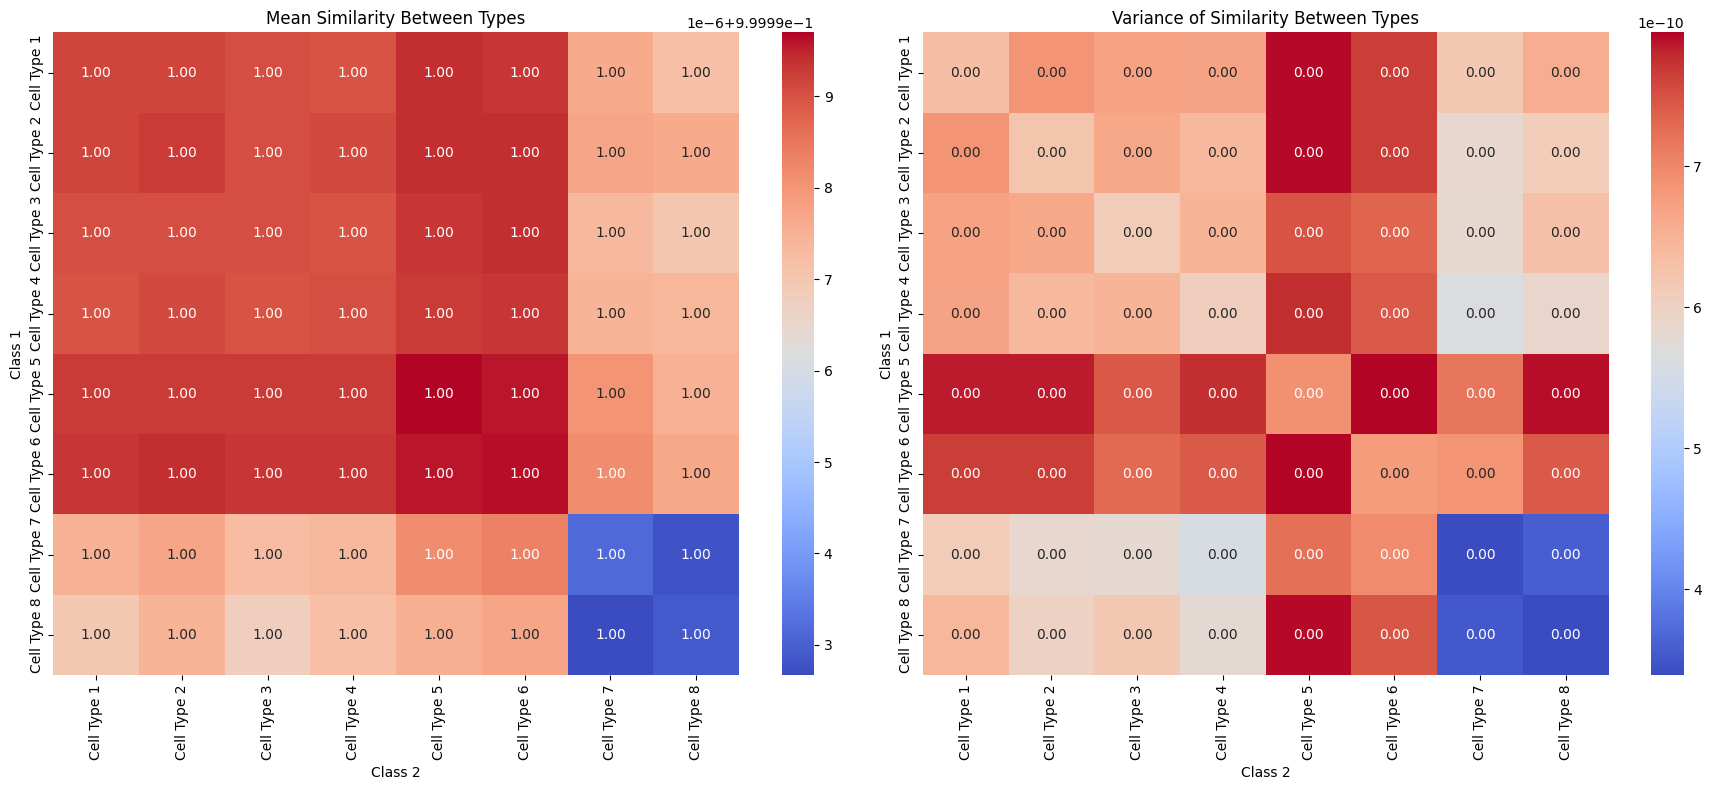

In [46]:
# File path
file_path = f'logs/simulated_100k_pred_depth_1_pred_emb_dim_192_enc_depth_3_enc_emb_dim_384_n_targets_9_n_contexts_1_target_mask_size_10_context_mask_size_1240_num_epochs_40_seq_len_cell_374_pos_learnable_0_seg_learnable_0_seq_len_neighborhood_1105_total/extracted_features/cell_embedding_weighted_average.h5ad'
adata = ad.read_h5ad(file_path)

# Load the .h5ad file
similarity_stats = compute_similarity_stats(adata,n_samples=None,type_key='cell_type')
plot_similarity_heatmaps(similarity_stats)

### 3.7.4 Niche Type Average

    Class 1  Class 2  Mean Similarity  Variance Similarity
0   Niche 7  Niche 7              1.0         8.484062e-14
1   Niche 7  Niche 4              1.0         8.471780e-14
2   Niche 7  Niche 6              1.0         1.057520e-13
3   Niche 7  Niche 3              1.0         5.071754e-14
4   Niche 7  Niche 2              1.0         9.692182e-14
..      ...      ...              ...                  ...
59  Niche 5  Niche 3              1.0         1.178639e-13
60  Niche 5  Niche 2              1.0         1.265079e-13
61  Niche 5  Niche 8              1.0         1.037678e-13
62  Niche 5  Niche 1              1.0         1.028632e-13
63  Niche 5  Niche 5              1.0         5.230267e-14

[64 rows x 4 columns]


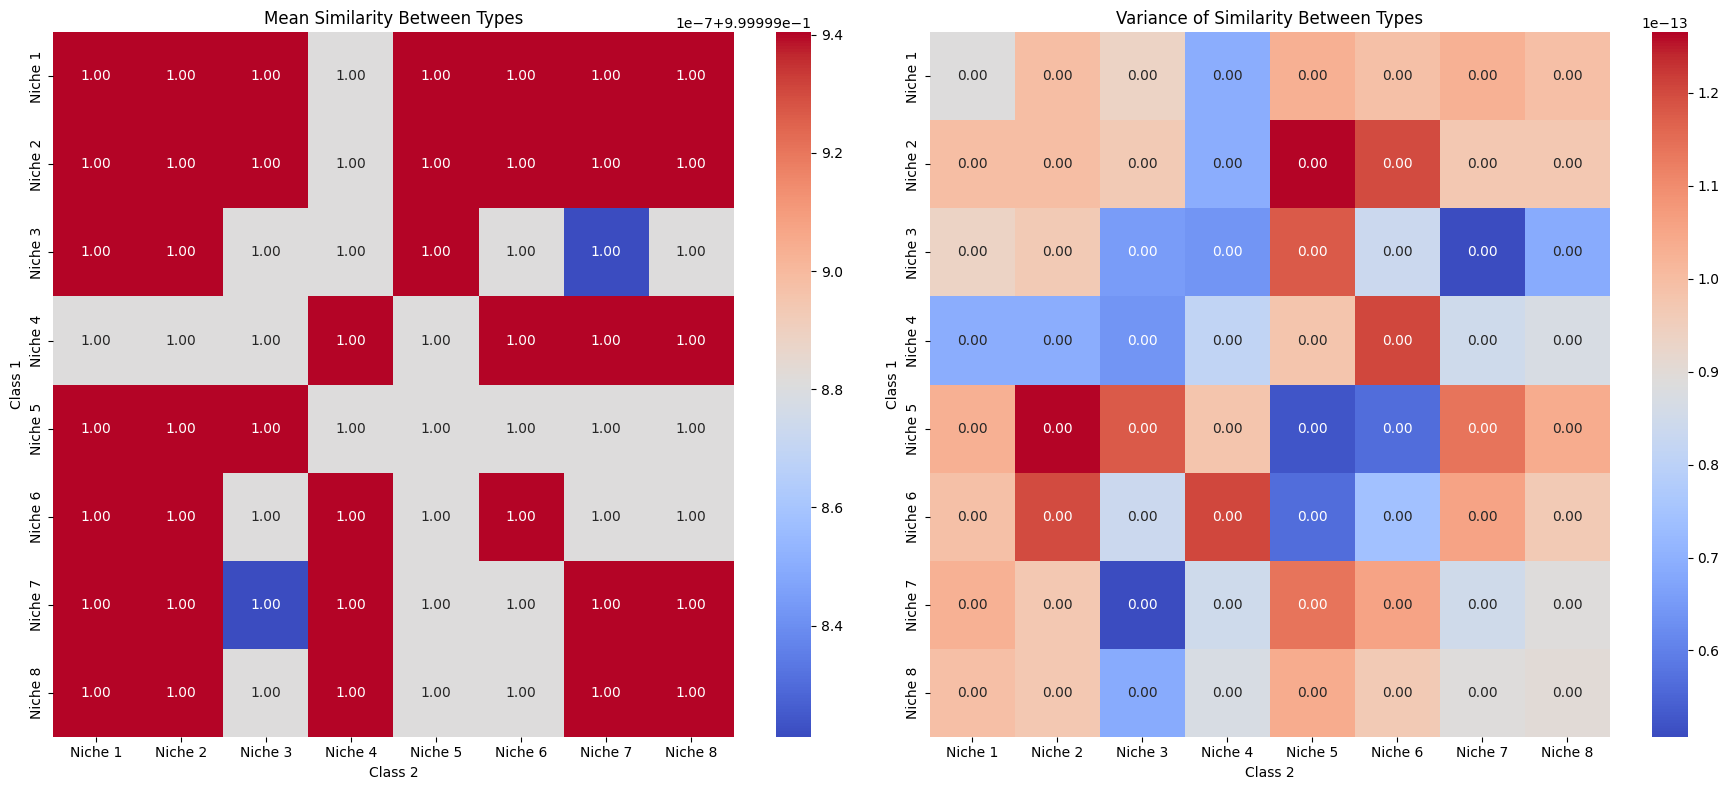

In [47]:
# File path
file_path = f'logs/simulated_100k_pred_depth_1_pred_emb_dim_192_enc_depth_3_enc_emb_dim_384_n_targets_9_n_contexts_1_target_mask_size_10_context_mask_size_1240_num_epochs_40_seq_len_cell_374_pos_learnable_0_seg_learnable_0_seq_len_neighborhood_1105_total/extracted_features/niche_embedding_average.h5ad'
adata = ad.read_h5ad(file_path)

# Load the .h5ad file
similarity_stats = compute_similarity_stats(adata,n_samples=None,type_key='niche_type')
plot_similarity_heatmaps(similarity_stats)

### 3.7.5 Niche Type CLS

    Class 1  Class 2  Mean Similarity  Variance Similarity
0   Niche 7  Niche 7              1.0         8.465011e-13
1   Niche 7  Niche 4              1.0         8.538031e-13
2   Niche 7  Niche 6              1.0         1.261870e-12
3   Niche 7  Niche 3              1.0         7.221848e-13
4   Niche 7  Niche 2              1.0         8.681743e-13
..      ...      ...              ...                  ...
59  Niche 5  Niche 3              1.0         1.152191e-12
60  Niche 5  Niche 2              1.0         1.107958e-12
61  Niche 5  Niche 8              1.0         1.126563e-12
62  Niche 5  Niche 1              1.0         9.591465e-13
63  Niche 5  Niche 5              1.0         6.236779e-13

[64 rows x 4 columns]


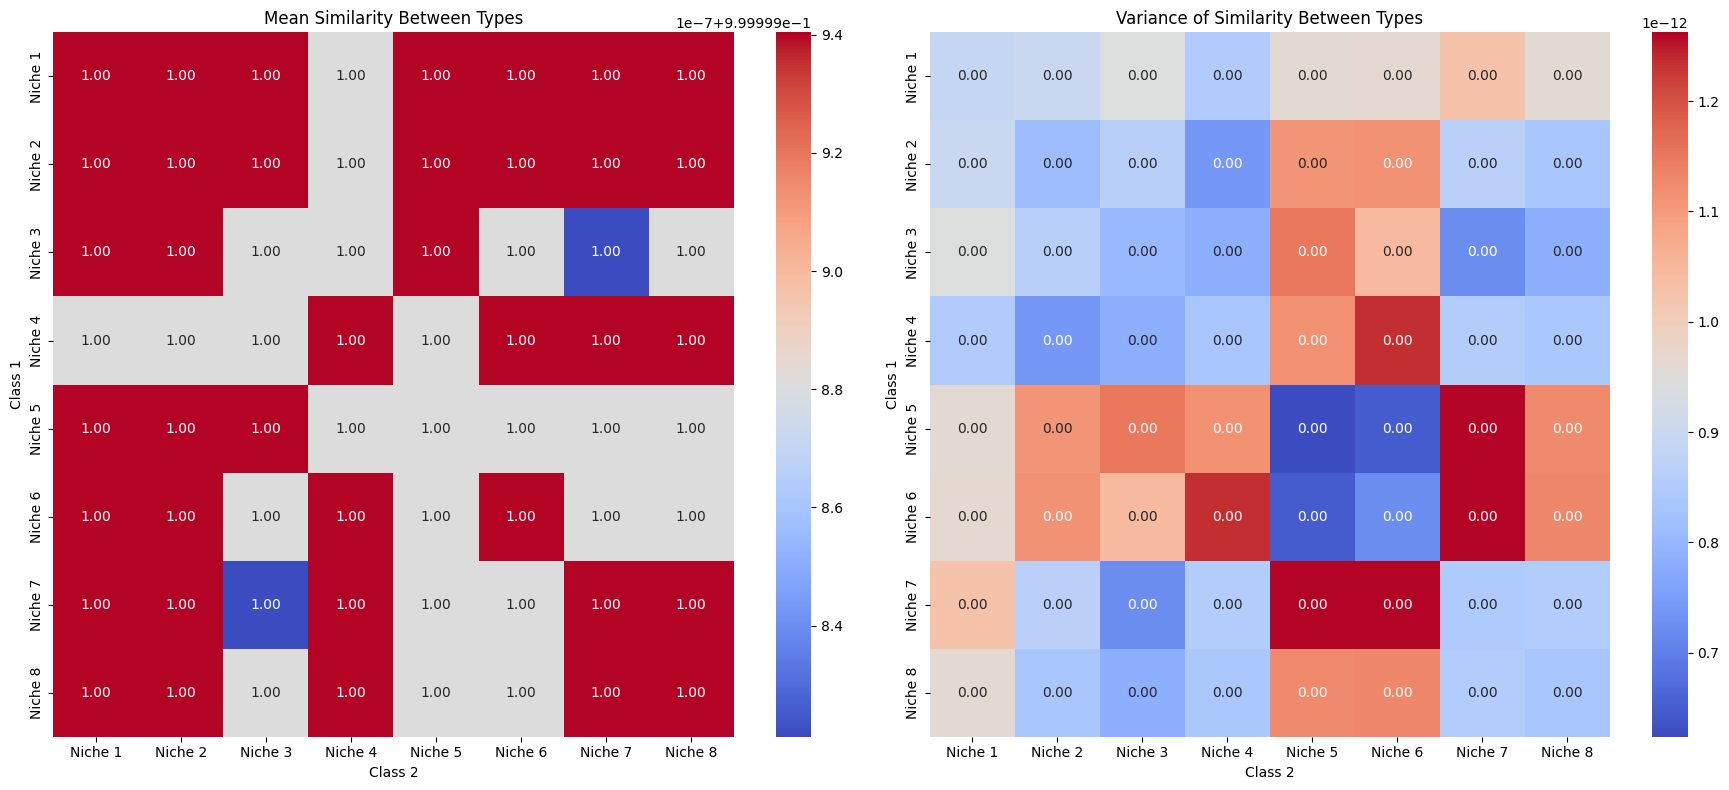

In [48]:
# File path
file_path = f'logs/simulated_100k_pred_depth_1_pred_emb_dim_192_enc_depth_3_enc_emb_dim_384_n_targets_9_n_contexts_1_target_mask_size_10_context_mask_size_1240_num_epochs_40_seq_len_cell_374_pos_learnable_0_seg_learnable_0_seq_len_neighborhood_1105_total/extracted_features/niche_embedding_cls.h5ad'
adata = ad.read_h5ad(file_path)

# Load the .h5ad file
similarity_stats = compute_similarity_stats(adata,n_samples=None,type_key='niche_type')
plot_similarity_heatmaps(similarity_stats)

### 3.7.6 Niche Type weighted_average

    Class 1  Class 2  Mean Similarity  Variance Similarity
0   Niche 7  Niche 7         0.999999         6.019270e-10
1   Niche 7  Niche 4         0.999999         6.403057e-10
2   Niche 7  Niche 6         0.999998         8.137960e-10
3   Niche 7  Niche 3         0.999999         6.692741e-10
4   Niche 7  Niche 2         0.999999         6.469775e-10
..      ...      ...              ...                  ...
59  Niche 5  Niche 3         0.999999         8.140419e-10
60  Niche 5  Niche 2         0.999999         7.876163e-10
61  Niche 5  Niche 8         0.999999         8.596941e-10
62  Niche 5  Niche 1         0.999999         7.899696e-10
63  Niche 5  Niche 5         0.999999         4.863588e-10

[64 rows x 4 columns]


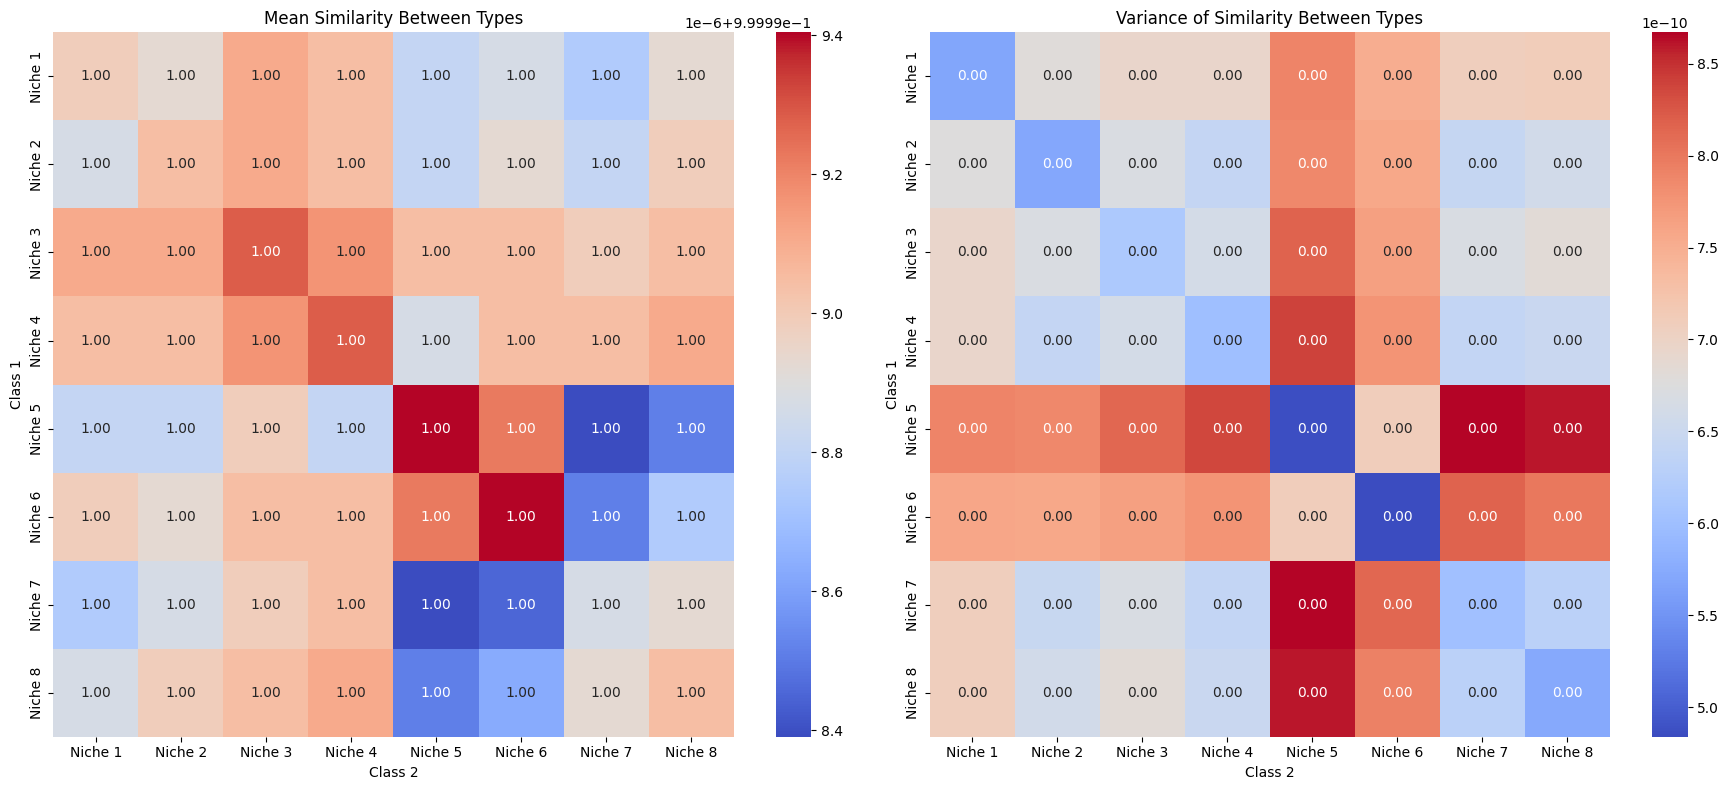

In [49]:
# File path
file_path = f'logs/simulated_100k_pred_depth_1_pred_emb_dim_192_enc_depth_3_enc_emb_dim_384_n_targets_9_n_contexts_1_target_mask_size_10_context_mask_size_1240_num_epochs_40_seq_len_cell_374_pos_learnable_0_seg_learnable_0_seq_len_neighborhood_1105_total/extracted_features/niche_embedding_weighted_average.h5ad'
adata = ad.read_h5ad(file_path)

# Load the .h5ad file
similarity_stats = compute_similarity_stats(adata,n_samples=None,type_key='niche_type')
plot_similarity_heatmaps(similarity_stats)